# MMRDR-XAI: Colab runner

Runs the full pipeline on a Colab GPU (tested on a T4) by calling the scripts in `scripts/`. No logic lives here, this notebook is just to run the code.

**Before running:** put `MMRDR-CFP/` (from figshare, DOI 10.6084/m9.figshare.29423747.v2) in a Drive folder and perform the data acquisition steps mentioned in mmrdr-eda.ipynb. After extracting and preprocessing the data, run this notebook for experimentation.
set `DRIVE` in the paths cell.
Set `GITHUB` to clone the code, or keep a copy of the repo on Drive. Checkpoints and results are written to `RUNS` on Drive so they survive disconnects.

# 1. Setup

In [ ]:
#mount drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
cd /content/drive/MyDrive/mmrdr

/content/drive/MyDrive/mmrdr


In [ ]:
!ls

'01_data_exploration (1).ipynb'   cache512.tar	 MMRDR-OCT   README.md
 01_data_exploration.ipynb	  eda		 MMRDR-UWF   runs
 29423747.zip			  MMRDR-CFP	 mmrdr-xai


In [ ]:
DRIVE = "/content/drive/MyDrive/mmrdr"
REPO  = "/content/mmrdr-xai"                     #code location on the VM
REPO_ZIP = f"{DRIVE}/mmrdr-xai.zip"
GITHUB = "https://github.com/hafsaabid416/mmrdr-xai-2026.git"
DATA  = "/content/data/MMRDR-CFP"
CACHE = "/content/cache512"
RUNS  = f"{DRIVE}/runs"                          #checkpoints + logs persist on Drive


import os, subprocess
if not os.path.exists(REPO):
    if GITHUB:
        subprocess.run(["git", "clone", GITHUB, REPO], check=True)
    else:                                        # otherwise use a copy of the repo on Drive
        subprocess.run(["cp", "-r", f"{DRIVE}/mmrdr-xai/mmrdr-xai", REPO], check=True)
os.chdir(REPO)
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install -r requirements.txt
!python -m pytest -q tests

name, memory.total [MiB]
Tesla T4, 15360 MiB
.............                                                            [100%]
=============================== warnings summary ===============================
tests/test_core.py::test_splits_have_no_leakage
  /content/mmrdr-xai/scripts/make_splits.py:60: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
    splits[["test_dup_within_test", "test_had_train_copy"]].fillna(False).astype(bool))

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
13 passed, 1 warning in 12.98s


# 2. Data

In [ ]:
#copying the images from Drive to local for faster reads

if not os.path.exists(f"{DATA}/FP.csv"):
    !mkdir -p /content/data && cp -r "{DRIVE}/MMRDR-CFP" /content/data/
!ls {DATA}/img | wc -l

11118


In [ ]:
#frozen leakage-safe split


if not os.path.exists("data/splits.csv"):
    !python scripts/make_splits.py --eda "{DRIVE}/eda/cfp_eda.csv" --out data/splits.csv
!cat data/splits_summary.json

{
  "counts": {
    "train": 7507,
    "val": 1252,
    "test": 2225
  },
  "grade_by_split": {
    "train": {
      "0": 4400,
      "1": 888,
      "2": 1326,
      "3": 431,
      "4": 462
    },
    "val": {
      "0": 734,
      "1": 148,
      "2": 221,
      "3": 72,
      "4": 77
    },
    "test": {
      "0": 1323,
      "1": 259,
      "2": 409,
      "3": 100,
      "4": 134
    }
  },
  "excluded": {
    "redundant copy within training": 76,
    "duplicate of a test image": 52,
    "duplicate group with conflicting grades": 6
  },
  "test_images_with_train_copy_removed": 46,
  "test_images_duplicated_within_test": 10,
  "val_fraction_of_pool": 0.1429,
  "seed": 42
}

In [ ]:
TAR = f"{DRIVE}/cache512.tar"
if not os.path.exists(CACHE):
    if os.path.exists(TAR):
        !mkdir -p {CACHE} && tar -xf "{TAR}" -C {CACHE}
    else:
        !python scripts/prepare_images.py --src {DATA} --out {CACHE}
        !tar -cf "{TAR}" -C {CACHE} .
!ls {CACHE} | wc -l

11118


# 3. Training

In [ ]:
# Train helper + stage A (no normalisation vs Graham vs CLAHE)


def train(cfg, name=None, extra=""):
    """Run one experiment; output streams live into the cell and is also saved to train.log."""
    name = name or cfg
    get_ipython().system(f'python scripts/train.py --config configs/{cfg}.yaml --splits data/splits.csv '
                         f'--images {CACHE} --out "{RUNS}/{name}" --resume {extra}')

train("A_baseline")
train("A_graham")
train("A_clahe")

A_baseline: already finished — skipping (use --force to retrain)
13:43:11 | INFO | torch 2.11.0+cu130 | GPU Tesla T4
13:43:12 | INFO | device=cuda | train=7507 val=1252 | normaliser=graham
13:43:12 | INFO | class counts=[4400, 888, 1326, 431, 462] weights=[0.5260000228881836, 0.8820000290870667, 0.7070000171661377, 1.4819999933242798, 1.402999997138977]
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 172MB/s]
13:43:18 | INFO | resumed at epoch 1
13:47:56 | INFO | ep 01 loss 0.7219 | val QWK 0.8866 F1 0.7032 acc 0.8083 ECE 0.029 | 273s 27 img/s *
13:52:36 | INFO | ep 02 loss 0.4700 | val QWK 0.8899 F1 0.7112 acc 0.8099 ECE 0.026 | 275s 27 img/s *
13:57:13 | INFO | ep 03 loss 0.2511 | val QWK 0.8940 F1 0.6921 acc 0.8075 ECE 0.096 | 275s 27 img/s *
14:01:58 | INFO | ep 04 loss 0.1053 | val QWK 0.8928 F1 0.6929 acc 0.8083 ECE 0.113 | 278s 27 img/s
14:06:33 | INFO | ep 05 loss

In [ ]:
# Validation summary of all finished runs
import pandas as pd, json, glob
def summary():
    rows = []
    for d in sorted(glob.glob(f"{RUNS}/*/val_metrics.json")):
        m = json.load(open(d)); name = d.split("/")[-2]
        rows.append({"run": name, "QWK": m["qwk"], "macro-F1": m["macro_f1"], "accuracy": m["accuracy"],
                     "ECE": m["ece"], "under-grading": m["under_grading_rate"],
                     "referable sens": m["referable"]["sensitivity"], "referable spec": m["referable"]["specificity"]})
    return pd.DataFrame(rows).set_index("run").round(4)
summary()

,QWK,macro-F1,accuracy,ECE,under-grading,referable sens,referable spec
run,,,,,,,
A_baseline,0.8929,0.7186,0.8035,0.0507,0.1150,0.7486,0.9626
A_clahe,0.8890,0.7011,0.8059,0.0743,0.1086,0.8081,0.9388
A_graham,0.8940,0.6921,0.8075,0.0957,0.1214,0.8162,0.9388


In [ ]:
# Models B (ordinal), C (ordinal + lesions) and D (concept bottleneck)

NORM = "none"     #using none as neither graham nor clahe improved substantially the performance. so using standard
for cfg in ["B_ordinal", "C_multitask", "D_bottleneck"]:
    train(cfg, f"{cfg}_{NORM}", f"data.normaliser={NORM}")
summary()

14:58:10 | INFO | torch 2.11.0+cu130 | GPU Tesla T4
14:58:10 | INFO | device=cuda | train=7507 val=1252 | normaliser=none
14:58:10 | INFO | class counts=[4400, 888, 1326, 431, 462] weights=[0.5260000228881836, 0.8820000290870667, 0.7070000171661377, 1.4819999933242798, 1.402999997138977]
15:00:17 | INFO | ep 00 loss 0.4402 | val QWK 0.8440 F1 0.5542 acc 0.7436 ECE 0.047 | 126s 60 img/s *
15:02:21 | INFO | ep 01 loss 0.2755 | val QWK 0.8715 F1 0.5972 acc 0.7628 ECE 0.036 | 123s 61 img/s *
15:04:26 | INFO | ep 02 loss 0.1918 | val QWK 0.8946 F1 0.6758 acc 0.7843 ECE 0.027 | 123s 61 img/s *
15:06:31 | INFO | ep 03 loss 0.1282 | val QWK 0.8840 F1 0.6704 acc 0.7939 ECE 0.080 | 124s 61 img/s
15:08:35 | INFO | ep 04 loss 0.0823 | val QWK 0.8798 F1 0.6296 acc 0.7764 ECE 0.118 | 123s 61 img/s
15:10:39 | INFO | ep 05 loss 0.0368 | val QWK 0.8782 F1 0.6551 acc 0.7947 ECE 0.138 | 123s 61 img/s
15:12:44 | INFO | ep 06 loss 0.0266 | val QWK 0.8844 F1 0.6547 acc 0.7867 ECE 0.148 | 123s 61 img/s
15:14

,QWK,macro-F1,accuracy,ECE,under-grading,referable sens,referable spec
run,,,,,,,
A_baseline,0.8929,0.7186,0.8035,0.0507,0.1150,0.7486,0.9626
A_clahe,0.8890,0.7011,0.8059,0.0743,0.1086,0.8081,0.9388
A_graham,0.8940,0.6921,0.8075,0.0957,0.1214,0.8162,0.9388
B_ordinal_none,0.8946,0.6758,0.7843,0.0271,0.0815,0.8595,0.9342
C_multitask_none,0.9104,0.7064,0.8211,0.1318,0.0958,0.8784,0.9274
D_bottleneck_none,0.8986,0.6799,0.8083,0.1696,0.1214,0.8378,0.9444


# 4. Evaluation on the test set

In [ ]:
# Evaluate the four final models

FINAL = ["A_baseline", "B_ordinal_none", "C_multitask_none", "D_bottleneck_none"]
MAIN  = "C_multitask_none"
for r in FINAL:
    get_ipython().system(f'python scripts/evaluate.py --run "{RUNS}/{r}" --splits data/splits.csv --images {CACHE}')

A_baseline: T=1.45 rule=argmax | test QWK 0.873 [0.855, 0.890] macro-F1 0.673 acc 0.782 | referable sens/spec 0.886/0.894 | ECE 0.070→0.027 | 90% sets: coverage 0.914, size 1.59 | flagged 32.4%
B_ordinal_none: T=1.22 rule=median | test QWK 0.881 [0.866, 0.895] macro-F1 0.634 acc 0.760 | referable sens/spec 0.902/0.905 | ECE 0.035→0.028 | 90% sets: coverage 0.903, size 1.62 | flagged 33.6%
C_multitask_none: T=3.62 rule=median | test QWK 0.883 [0.867, 0.898] macro-F1 0.685 acc 0.812 | referable sens/spec 0.877/0.906 | ECE 0.137→0.022 | 90% sets: coverage 0.940, size 1.70 | flagged 32.4%
D_bottleneck_none: T=0.49 rule=argmax | test QWK 0.879 [0.862, 0.894] macro-F1 0.643 acc 0.791 | referable sens/spec 0.896/0.886 | ECE 0.153→0.049 | 90% sets: coverage 0.932, size 1.99 | flagged 33.7%


In [ ]:
# Test-set summary table (also saved as runs/test_summary.csv)
def test_summary():
    rows = []
    for r in FINAL:
        t = json.load(open(f"{RUNS}/{r}/eval/test_metrics.json"))["test"]; c = t["ci95"]
        f = lambda k: f"{c[k][0]:.3f} [{c[k][1]:.3f}, {c[k][2]:.3f}]"
        rows.append({"run": r, "QWK [95% CI]": f("qwk"), "macro-F1": f("macro_f1"), "accuracy": f("accuracy"),
                     "referable sens": f("referable_sensitivity"), "referable spec": f("referable_specificity"),
                     "STDR sens": f("sight_threatening_sensitivity"), "under-grading": round(t["under_grading_rate"], 3),
                     "distant errors": round(t["distant_error_rate"], 3), "missed STDR (≤ Mild)": t["missed_sight_threatening"],
                     "ECE raw→cal": f"{t['ece_uncalibrated']:.3f}→{t['ece_calibrated']:.3f}",
                     "90% set coverage": round(t["conformal"]["coverage"], 3), "mean set size": round(t["conformal"]["mean_set_size"], 2),
                     "flagged": f"{t['review_flags']['any_flag']['rate']:.1%}"})
    return pd.DataFrame(rows).set_index("run")
ts = test_summary(); ts.to_csv(f"{RUNS}/test_summary.csv"); ts

,QWK [95% CI],macro-F1,accuracy,referable sens,referable spec,STDR sens,under-grading,distant errors,missed STDR (≤ Mild),ECE raw→cal,90% set coverage,mean set size,flagged
run,,,,,,,,,,,,,
A_baseline,"0.873 [0.855, 0.890]","0.673 [0.646, 0.698]","0.782 [0.765, 0.798]","0.886 [0.861, 0.910]","0.894 [0.879, 0.909]","0.923 [0.887, 0.956]",0.125,0.030,15,0.070→0.027,0.914,1.59,32.4%
B_ordinal_none,"0.881 [0.866, 0.895]","0.634 [0.605, 0.659]","0.760 [0.741, 0.777]","0.902 [0.878, 0.924]","0.905 [0.891, 0.919]","0.927 [0.892, 0.961]",0.093,0.029,9,0.035→0.028,0.903,1.62,33.6%
C_multitask_none,"0.883 [0.867, 0.898]","0.685 [0.656, 0.711]","0.812 [0.796, 0.827]","0.877 [0.852, 0.902]","0.906 [0.891, 0.920]","0.953 [0.925, 0.979]",0.113,0.042,7,0.137→0.022,0.940,1.70,32.4%
D_bottleneck_none,"0.879 [0.862, 0.894]","0.643 [0.614, 0.670]","0.791 [0.774, 0.808]","0.896 [0.870, 0.919]","0.886 [0.870, 0.901]","0.902 [0.860, 0.939]",0.109,0.040,6,0.153→0.049,0.932,1.99,33.7%


In [ ]:
# Share of test images sent for review, per flag type

for r in FINAL:
    rf = json.load(open(f"{RUNS}/{r}/eval/test_metrics.json"))["test"]["review_flags"]
    print(r, {k: f"{v['rate']:.1%}" for k, v in rf.items()})

A_baseline {'referral_uncertain': '24.6%', 'urgency_uncertain': '15.5%', 'any_flag': '32.4%', 'multi_grade_set': '45.4%'}
B_ordinal_none {'referral_uncertain': '26.4%', 'urgency_uncertain': '13.3%', 'any_flag': '33.6%', 'multi_grade_set': '50.9%'}
C_multitask_none {'referral_uncertain': '23.6%', 'urgency_uncertain': '14.5%', 'pdr_signs_but_graded_below_4': '0.6%', 'lesions_but_graded_0': '0.8%', 'vb_irma_but_graded_below_3': '0.0%', 'any_flag': '32.4%', 'multi_grade_set': '57.0%'}
D_bottleneck_none {'referral_uncertain': '22.7%', 'urgency_uncertain': '16.9%', 'pdr_signs_but_graded_below_4': '0.9%', 'lesions_but_graded_0': '1.4%', 'vb_irma_but_graded_below_3': '0.0%', 'any_flag': '33.7%', 'multi_grade_set': '88.9%'}


# 5. Robustness and Explanations

In [ ]:
# Image-quality robustness (A and C) and Grad-CAM explanations (C and D)

for r in ["A_baseline", MAIN]:
    get_ipython().system(f'python scripts/robustness.py --run "{RUNS}/{r}" --splits data/splits.csv --images {CACHE}')
for r in [MAIN, "D_bottleneck_none"]:
    get_ipython().system(f'python scripts/explain.py --run "{RUNS}/{r}" --splits data/splits.csv --images {CACHE}')

clean        QWK 0.873 | ref sens 0.886 spec 0.894 | set size 1.59 | grade-0 false referral 0.026
blur σ=1     QWK 0.858 | ref sens 0.855 spec 0.917 | set size 1.61 | grade-0 false referral 0.016
blur σ=2     QWK 0.830 | ref sens 0.835 spec 0.921 | set size 1.60 | grade-0 false referral 0.025
blur σ=4     QWK 0.736 | ref sens 0.849 spec 0.822 | set size 1.82 | grade-0 false referral 0.117
dark γ=1.5   QWK 0.852 | ref sens 0.855 spec 0.917 | set size 1.51 | grade-0 false referral 0.016
dark γ=2.5   QWK 0.721 | ref sens 0.689 spec 0.948 | set size 1.53 | grade-0 false referral 0.014
JPEG q=30    QWK 0.789 | ref sens 0.882 spec 0.828 | set size 1.65 | grade-0 false referral 0.097
JPEG q=10    QWK 0.371 | ref sens 0.949 spec 0.382 | set size 2.12 | grade-0 false referral 0.578
clean        QWK 0.883 | ref sens 0.877 spec 0.906 | set size 1.70 | grade-0 false referral 0.017
blur σ=1     QWK 0.891 | ref sens 0.891 spec 0.910 | set size 1.77 | grade-0 false referral 0.015
blur σ=2     QWK 0.8

eval/confusion_matrix.png


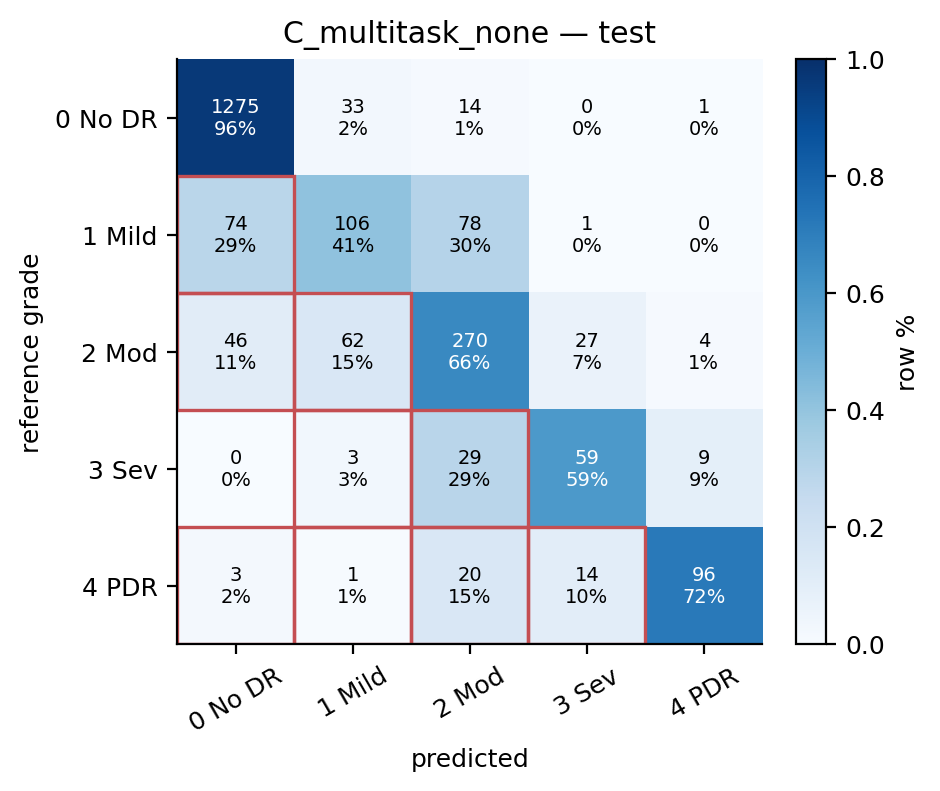

eval/reliability.png


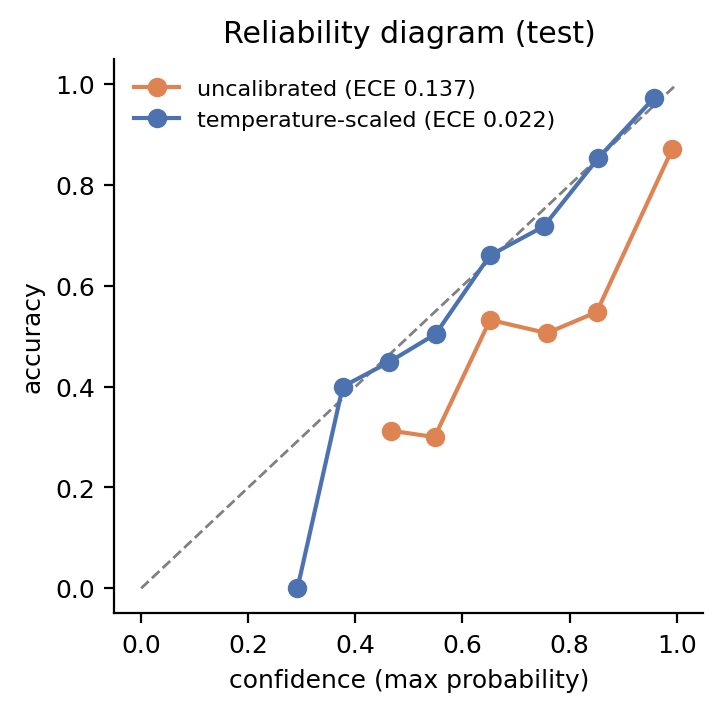

eval/selective_prediction.png


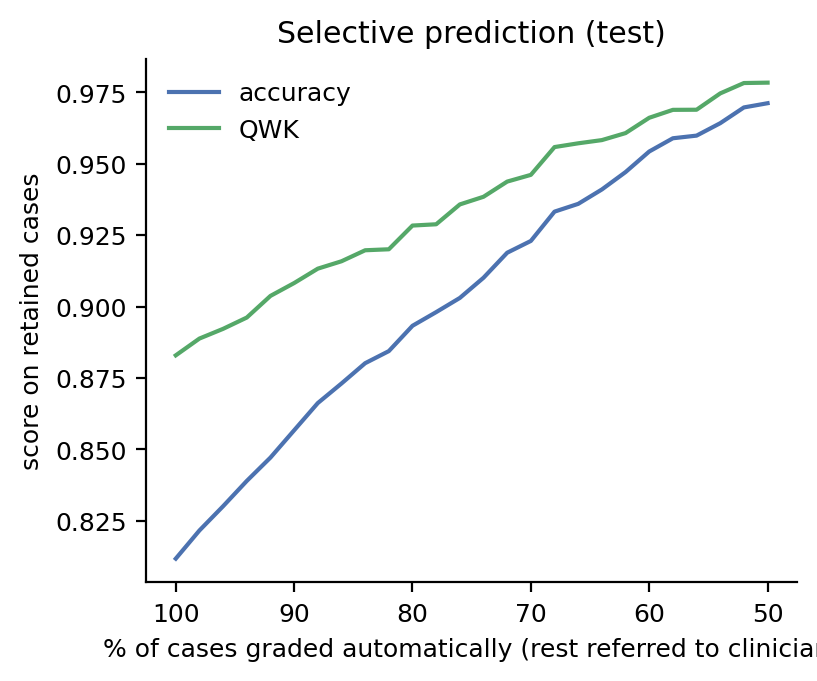

robustness/robustness.png


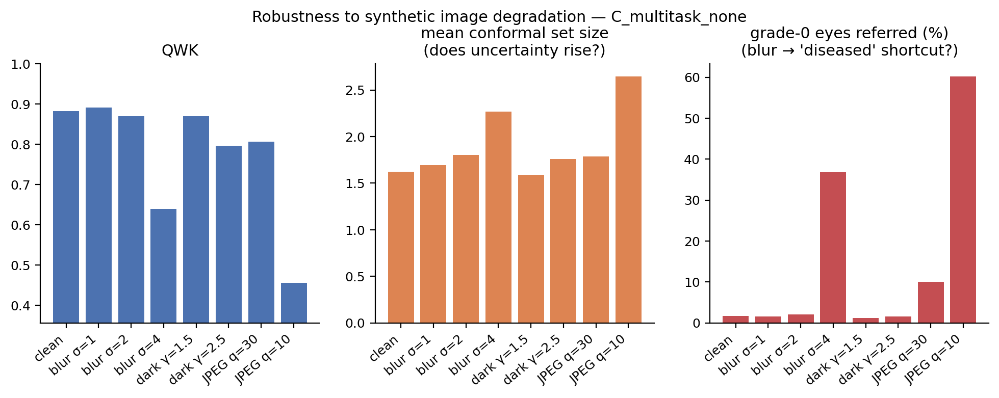

explain/gallery.png


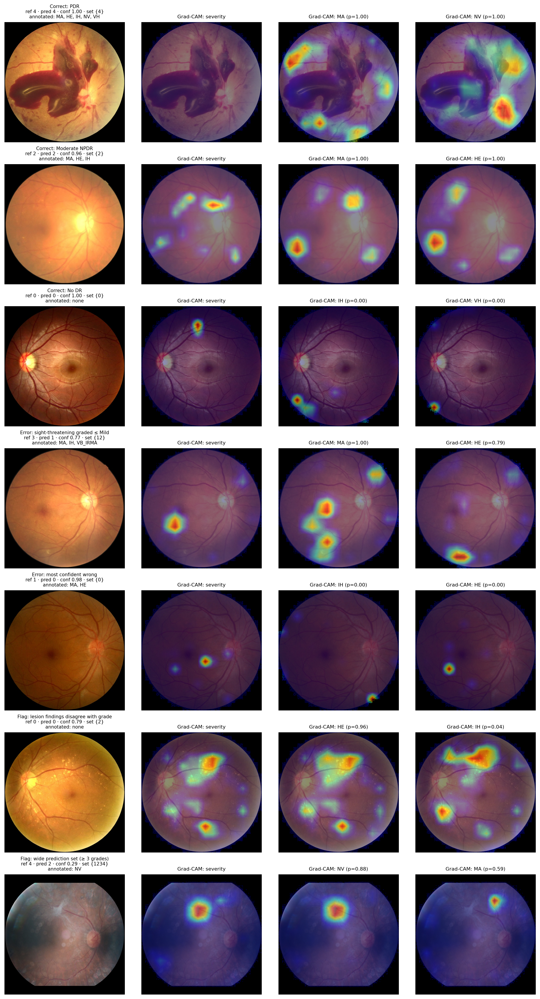

explain/sanity_check.png


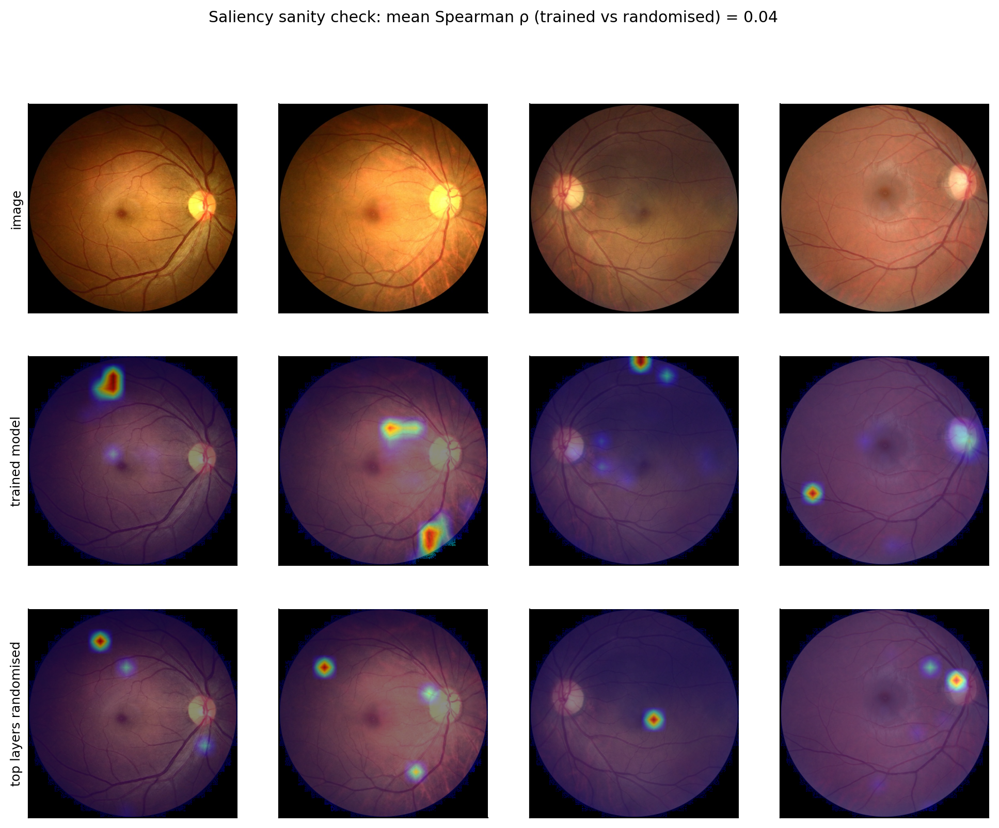

In [ ]:
#Show the main figures for model C
from IPython.display import Image, display
for f in ["eval/confusion_matrix.png", "eval/reliability.png", "eval/selective_prediction.png",
          "robustness/robustness.png", "explain/gallery.png", "explain/sanity_check.png"]:
    print(f); display(Image(f"{RUNS}/{MAIN}/{f}", width=900))

# 6 · Review-flag workload vs conformal α (model C)

In [ ]:
# Trade-off between review rate and missed cases for several α values

import sys, numpy as np, torch, yaml; sys.path.insert(0, "src")
from mmrdr.calibration import fit_conformal, prediction_sets
from mmrdr.flags import review_flags
from mmrdr.metrics import predict
from mmrdr.models import grade_probs
from mmrdr import LESIONS

r = "C_multitask_none"
fit = json.load(open(f"{RUNS}/{r}/eval/test_metrics.json"))["fitted_on_validation"]
head = yaml.safe_load(open(f"{RUNS}/{r}/config.yaml"))["model"]["grade_head"]
val = pd.read_csv(f"{RUNS}/{r}/val_predictions.csv"); te = pd.read_csv(f"{RUNS}/{r}/eval/test_predictions.csv")
P = lambda d: grade_probs(torch.tensor(d.filter(like="logit_").values, dtype=torch.float32), head, fit["temperature"]).numpy()
pv, pt, yv, y = P(val), P(te), val.grade.values, te.grade.values
yhat = predict(pt, fit["decision_rule"]); les = te[[f"lesion_{l}" for l in LESIONS]].values
rows = []
for a in [0.05, 0.10, 0.20, 0.30]:
    f = review_flags(yhat, prediction_sets(pt, fit_conformal(pv, yv, a), yhat), les)
    auto = ~f.any_flag.values
    rows.append({"alpha": a, "flagged %": 100 * f.any_flag.mean(),
                 "error % auto": 100 * (yhat[auto] != y[auto]).mean(),
                 "error % flagged": 100 * (yhat[~auto] != y[~auto]).mean(),
                 "missed referable in auto (true≥2, pred≤1)": int(((y >= 2) & (yhat <= 1) & auto).sum()),
                 "missed STDR in auto (true≥3, pred≤1)": int(((y >= 3) & (yhat <= 1) & auto).sum())})
tradeoff = pd.DataFrame(rows).round(1); tradeoff.to_csv(f"{RUNS}/{r}/eval/flag_tradeoff.csv", index=False); tradeoff

,alpha,flagged %,error % auto,error % flagged,"missed referable in auto (true≥2, pred≤1)","missed STDR in auto (true≥3, pred≤1)"
0,0.0,36.5,6.3,40.6,18,1
1,0.1,32.4,8.2,41.0,31,1
2,0.2,21.3,12.6,41.9,72,3
3,0.3,13.3,15.8,39.0,95,5


# 7. Clinician intervention on model D

max |logit| reconstruction gap: 0.003
missed referable / STDR = point prediction ≤ Mild; 'at threshold' = below the validation referral threshold
model only:       QWK 0.879 acc 0.790 missed referable 99 missed STDR 6 | at threshold: referable 67, STDR 23
flagged-only k=2: QWK 0.923 acc 0.874 missed referable 65 missed STDR 6 | 1498 edits on 749 images
all corrected:    QWK 0.938 acc 0.928 missed referable 74 missed STDR 19
add-only (all images)     QWK 0.941 acc 0.869 missed referable 7 missed STDR 1 | at threshold: referable 3, STDR 6 | 1641 edits
remove-only (all images)  QWK 0.847 acc 0.839 missed referable 173 missed STDR 30 | at threshold: referable 104, STDR 93 | 9433 edits
add-only (flagged)        QWK 0.910 acc 0.828 missed referable 37 missed STDR 3 | at threshold: referable 35, STDR 9 | 1131 edits
remove-only (flagged)     QWK 0.887 acc 0.852 missed referable 160 missed STDR 18 | at threshold: referable 94, STDR 67 | 3526 edits


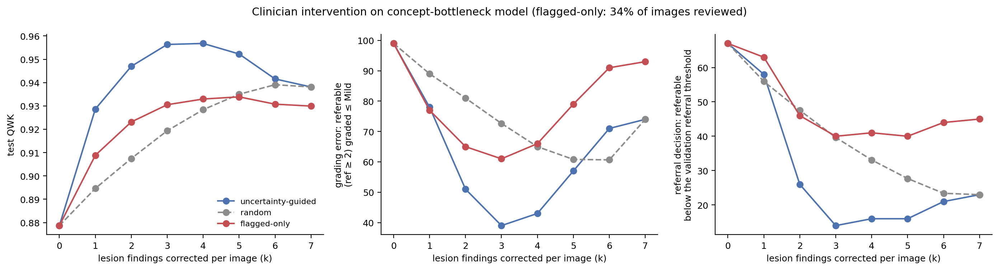

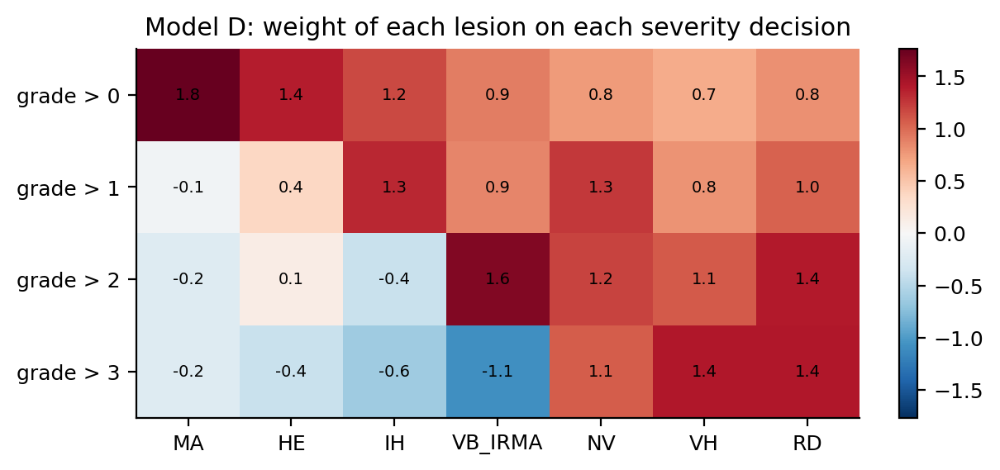

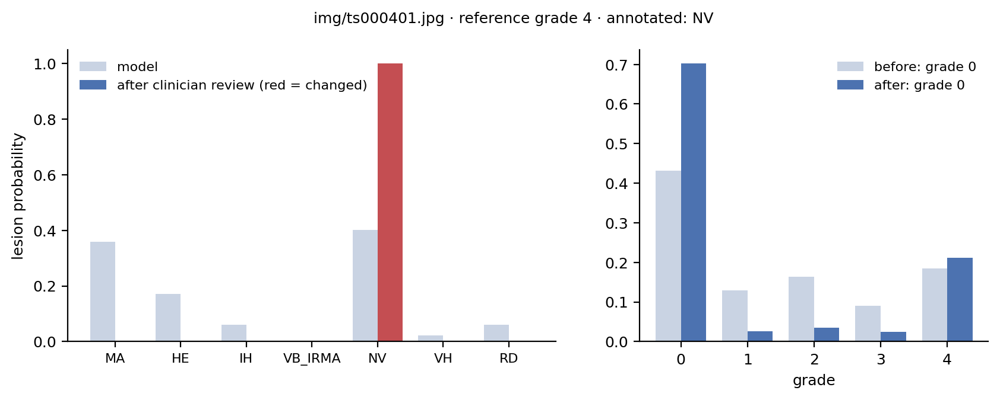

,policy,k,qwk,accuracy,macro_f1,referable_sens,referable_spec,missed_referable,missed_sight_threatening,referable_missed_at_thr,sight_threatening_missed_at_thr,lesion_edits,images_reviewed
0,model only,0.0,0.879,0.790,0.642,0.896,0.886,99.00,6.00,67.00,23.00,0.0,0.0
1,uncertainty-guided,1.0,0.929,0.872,0.753,0.910,0.917,78.00,9.00,58.00,39.00,2225.0,2225.0
2,random,1.0,0.895,0.812,0.674,0.913,0.892,89.00,5.50,55.95,24.05,2225.0,2225.0
3,flagged-only,1.0,0.909,0.850,0.731,0.902,0.918,77.00,8.00,63.00,40.00,749.0,749.0
4,uncertainty-guided,2.0,0.947,0.903,0.788,0.960,0.923,51.00,7.00,26.00,41.00,4450.0,2225.0
5,random,2.0,0.908,0.832,0.699,0.926,0.898,81.00,5.95,47.55,27.00,4450.0,2225.0
6,flagged-only,2.0,0.923,0.874,0.766,0.928,0.930,65.00,6.00,46.00,41.00,1498.0,749.0
7,uncertainty-guided,3.0,0.956,0.921,0.800,0.978,0.924,39.00,7.00,14.00,61.00,6675.0,2225.0
8,random,3.0,0.919,0.853,0.726,0.938,0.904,72.65,6.65,39.65,31.10,6675.0,2225.0
9,flagged-only,3.0,0.930,0.892,0.793,0.938,0.932,61.00,7.00,40.00,49.00,2247.0,749.0


In [ ]:
# Simulate clinicians correcting D's lesion findings; show curves, weights and an example
from IPython.display import Image, display
get_ipython().system(f'python scripts/intervention.py --run "{RUNS}/D_bottleneck_none" --splits data/splits.csv')
for f in ["intervention_curve.png", "concept_weights.png", "example_0.png"]:
    display(Image(f"{RUNS}/D_bottleneck_none/intervention/{f}", width=900))
pd.read_csv(f"{RUNS}/D_bottleneck_none/intervention/intervention.csv").round(3)

# 8. Audit checks

In [ ]:
#audit checks
get_ipython().system(f'python scripts/audit_checks.py --runs "{RUNS}" --splits data/splits.csv --models A_baseline B_ordinal_none C_multitask_none D_bottleneck_none --bottleneck D_bottleneck_none')

/content/mmrdr-xai
A · consistency: {'A_baseline': 'consistent', 'B_ordinal_none': 'consistent', 'C_multitask_none': 'consistent', 'D_bottleneck_none': 'consistent'}
    D_bottleneck_none: referral FN eval/recomputed/intervention = 67/67/67; urgent FN = 23/23/23; QWK eval/intervention = 0.879/0.879

B · conformal coverage per grade (target 0.90):
run    A_baseline  B_ordinal_none  C_multitask_none  D_bottleneck_none
grade                                                                 
0           0.881           0.890             0.892              0.884
1           0.934           0.892             0.880              0.915
2           0.905           0.917             0.907              0.888
3           0.960           0.940             0.950              0.890
4           0.896           0.910             0.910              0.918
all         0.896           0.899             0.897              0.890

C · flag contributions (exploratory — rules refined during the study):

A_baseline